# 04 - Employee Attrition: Initial EDA (Capstone Progress)
**Task 1, Section 11 - Major Project Progress:** *AI-Based Employee Attrition Prediction System*

Goal for Task 1: load the employee dataset, check quality, understand what is associated with attrition and document initial observations.

In [1]:
import warnings; warnings.filterwarnings("ignore")
import sys; sys.path.append("../src")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from eda_utils import missing_report, iqr_outliers, save_fig, clean_columns
sns.set_theme(style="whitegrid", palette="deep")
%matplotlib inline

## 1. Load and inspect

In [2]:
emp = pd.read_csv("../data/employee_data.csv")
print("Shape:", emp.shape)
emp.head()

Shape: (1200, 11)


,EmployeeID,Age,Department,JobLevel,MonthlyIncome,YearsAtCompany,DistanceFromHome,OverTime,JobSatisfaction,WorkLifeBalance,Attrition
0,1,31,Finance,2,7870.0,6,15,Yes,4.0,4,No
1,2,33,Sales,1,5320.0,3,5,Yes,1.0,2,No
2,3,30,R&D,1,4480.0,3,3,Yes,3.0,1,No
3,4,40,Sales,2,8980.0,6,23,No,3.0,4,No
4,5,47,R&D,2,8610.0,9,13,No,3.0,2,No


In [3]:
emp.info()
print()
print("Duplicates:", emp.duplicated().sum())
missing_report(emp)

<class 'pandas.DataFrame'>
RangeIndex: 1200 entries, 0 to 1199
Data columns (total 11 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   EmployeeID        1200 non-null   int64  
 1   Age               1200 non-null   int64  
 2   Department        1200 non-null   str    
 3   JobLevel          1200 non-null   int64  
 4   MonthlyIncome     1185 non-null   float64
 5   YearsAtCompany    1200 non-null   int64  
 6   DistanceFromHome  1200 non-null   int64  
 7   OverTime          1200 non-null   str    
 8   JobSatisfaction   1190 non-null   float64
 9   WorkLifeBalance   1200 non-null   int64  
 10  Attrition         1200 non-null   str    
dtypes: float64(2), int64(6), str(3)
memory usage: 103.3 KB

Duplicates: 0


,missing,percent
MonthlyIncome,15,1.25
JobSatisfaction,10,0.83


## 2. Clean

In [4]:
emp["MonthlyIncome"] = emp["MonthlyIncome"].fillna(emp.groupby("JobLevel")["MonthlyIncome"].transform("median"))
emp["JobSatisfaction"] = emp["JobSatisfaction"].fillna(emp["JobSatisfaction"].median())
emp = emp.drop(columns="EmployeeID")
emp["attrition_flag"] = (emp["Attrition"] == "Yes").astype(int)
print("Missing after cleaning:", emp.isnull().sum().sum())
emp.to_csv("../data/employee_data_clean.csv", index=False)
emp.describe().round(2)

Missing after cleaning: 0


,Age,JobLevel,MonthlyIncome,YearsAtCompany,DistanceFromHome,JobSatisfaction,WorkLifeBalance,attrition_flag
count,1200.0,1200.00,1200.00,1200.00,1200.00,1200.00,1200.00,1200.00
mean,36.9,2.00,8387.28,5.16,15.07,2.50,2.49,0.26
std,8.7,0.83,2722.59,4.07,8.23,1.13,1.11,0.44
min,20.0,1.00,2810.00,0.00,1.00,1.00,1.00,0.00
25%,31.0,1.00,6330.00,2.00,8.00,1.00,2.00,0.00
50%,37.0,2.00,8150.00,4.00,15.00,2.00,2.00,0.00
75%,43.0,2.00,9910.00,8.00,22.00,4.00,3.00,1.00
max,60.0,5.00,18880.00,23.00,29.00,4.00,4.00,1.00


## 3. Target variable

Attrition rate: 26.1%  ->  class imbalance to handle in Task 2


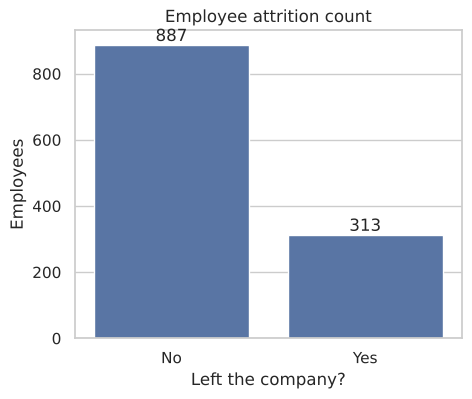

In [5]:
rate = emp["attrition_flag"].mean()
print(f"Attrition rate: {rate:.1%}  ->  class imbalance to handle in Task 2")
plt.figure(figsize=(5, 4))
ax = sns.countplot(data=emp, x="Attrition", order=["No", "Yes"])
ax.bar_label(ax.containers[0]); ax.set_title("Employee attrition count"); ax.set_xlabel("Left the company?"); ax.set_ylabel("Employees")
save_fig("employee_attrition_count.png"); plt.show()

## 4. Attrition by category

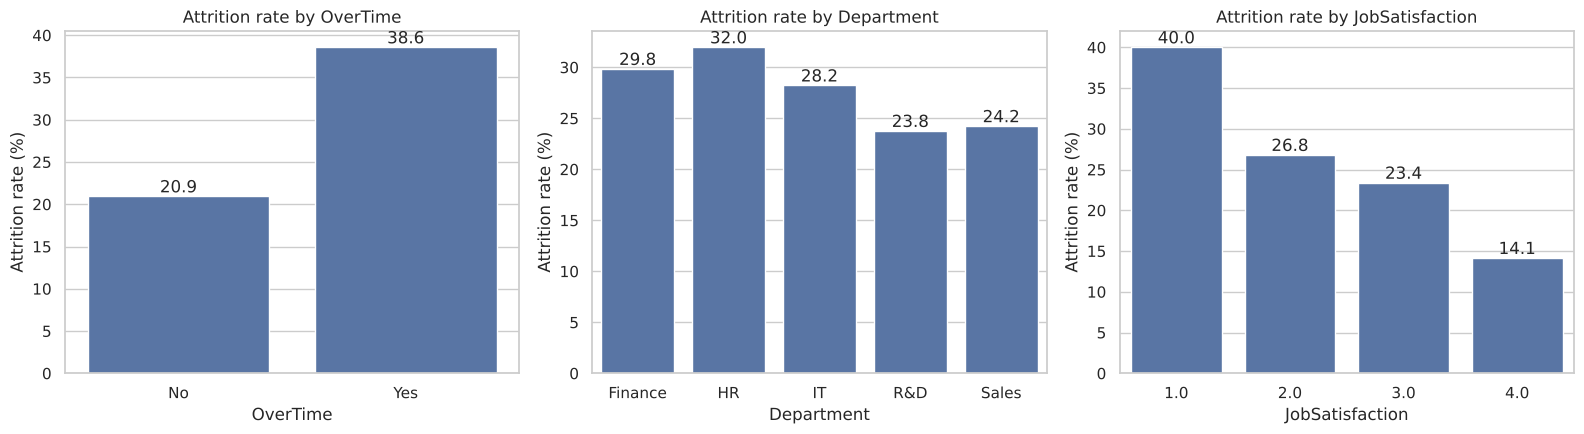

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, col in zip(axes, ["OverTime", "Department", "JobSatisfaction"]):
    t = emp.groupby(col)["attrition_flag"].mean().mul(100)
    sns.barplot(x=t.index.astype(str), y=t.values, ax=ax)
    ax.set_title(f"Attrition rate by {col}"); ax.set_xlabel(col); ax.set_ylabel("Attrition rate (%)")
    ax.bar_label(ax.containers[0], fmt="%.1f")
plt.tight_layout(); save_fig("employee_attrition_by_category.png"); plt.show()

## 5. Numeric features vs attrition

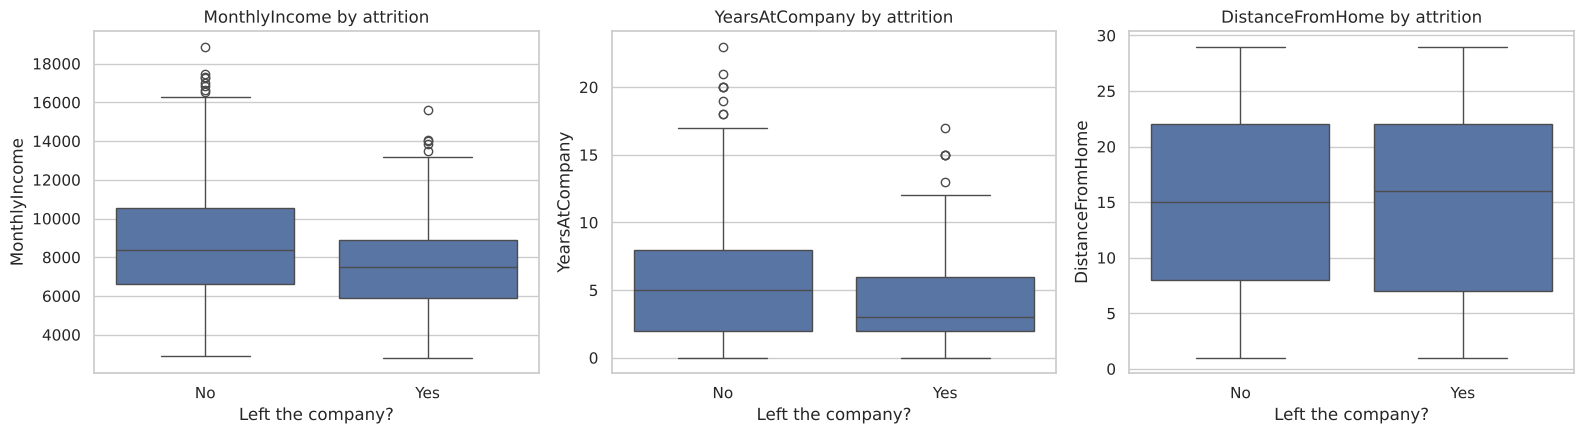

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, col in zip(axes, ["MonthlyIncome", "YearsAtCompany", "DistanceFromHome"]):
    sns.boxplot(data=emp, x="Attrition", y=col, order=["No", "Yes"], ax=ax)
    ax.set_title(f"{col} by attrition"); ax.set_xlabel("Left the company?"); ax.set_ylabel(col)
plt.tight_layout(); save_fig("employee_numeric_boxplots.png"); plt.show()

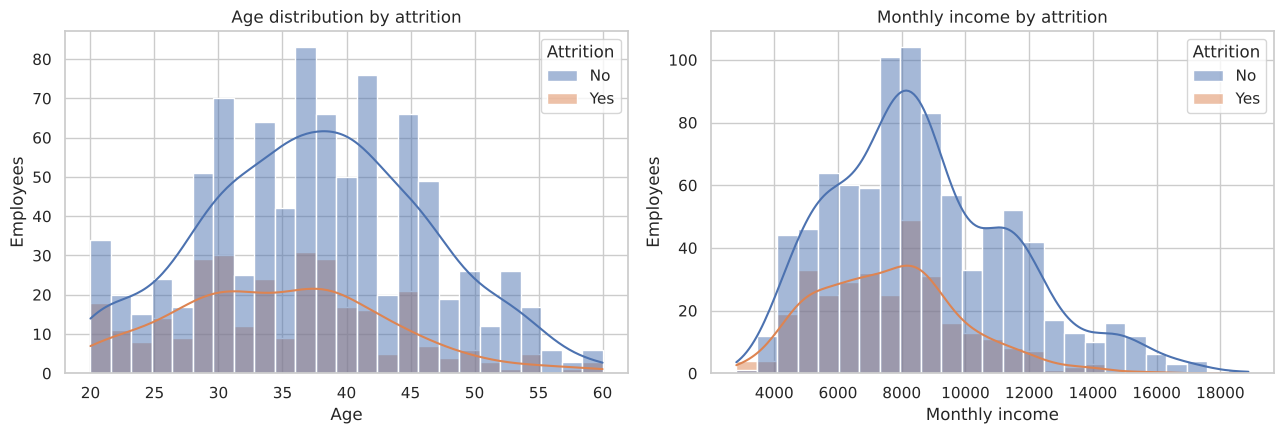

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
sns.histplot(data=emp, x="Age", hue="Attrition", kde=True, bins=25, ax=axes[0]); axes[0].set_title("Age distribution by attrition"); axes[0].set_xlabel("Age"); axes[0].set_ylabel("Employees")
sns.histplot(data=emp, x="MonthlyIncome", hue="Attrition", kde=True, bins=25, ax=axes[1]); axes[1].set_title("Monthly income by attrition"); axes[1].set_xlabel("Monthly income"); axes[1].set_ylabel("Employees")
plt.tight_layout(); save_fig("employee_histograms.png"); plt.show()

## 6. Correlation heatmap

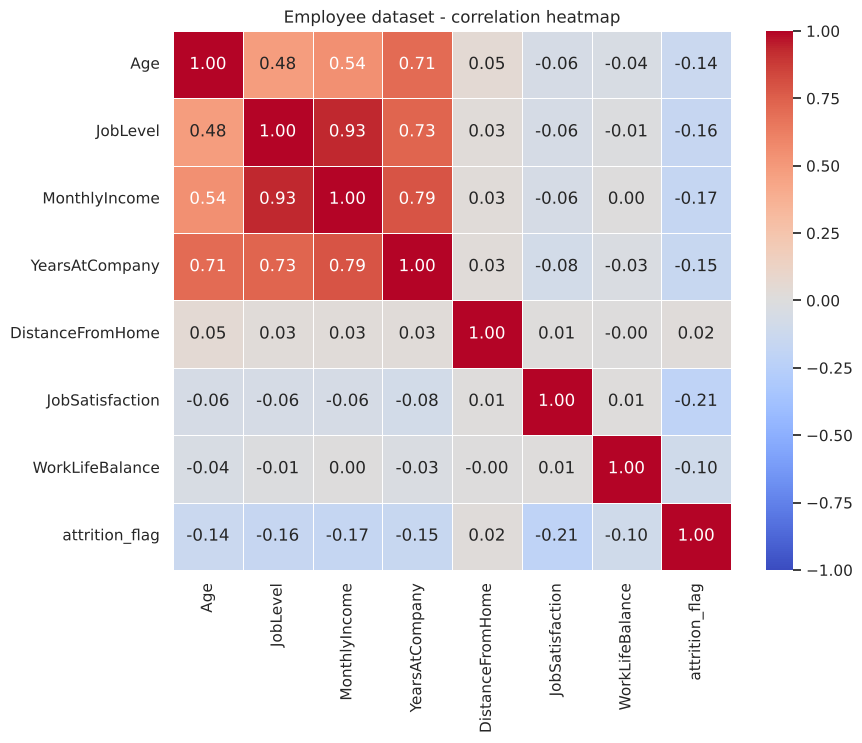

JobSatisfaction    -0.21
MonthlyIncome      -0.17
JobLevel           -0.16
YearsAtCompany     -0.15
Age                -0.14
WorkLifeBalance    -0.10
DistanceFromHome    0.02
Name: attrition_flag, dtype: float64

In [9]:
corr = emp.select_dtypes("number").corr().round(2)
plt.figure(figsize=(9, 7))
sns.heatmap(corr, annot=True, cmap="coolwarm", vmin=-1, vmax=1, fmt=".2f", linewidths=.5)
plt.title("Employee dataset - correlation heatmap")
save_fig("employee_correlation_heatmap.png"); plt.show()
corr["attrition_flag"].drop("attrition_flag").sort_values()

## 7. Initial observations (data-driven)

In [10]:
ot = emp.groupby("OverTime")["attrition_flag"].mean()
sat = emp.groupby("JobSatisfaction")["attrition_flag"].mean()
c = emp.select_dtypes("number").corr()["attrition_flag"]
print("1. Overall attrition rate is %.1f%% - imbalanced target (use stratified split, F1/recall, class weights)." % (rate * 100))
print("2. Overtime is the clearest signal: %.1f%% attrition with overtime vs %.1f%% without." % (ot["Yes"] * 100, ot["No"] * 100))
print("3. Lower job satisfaction -> higher attrition (satisfaction 1: %.1f%%, 4: %.1f%%)." % (sat.loc[1] * 100, sat.loc[4] * 100))
print("4. Income and tenure are negatively correlated with attrition (r = %.2f and %.2f)." % (c["MonthlyIncome"], c["YearsAtCompany"]))
print("5. Commute distance has almost no linear relationship with attrition (r = %.2f)." % c["DistanceFromHome"])
print("6. Departments differ only modestly: %s" % (emp.groupby("Department")["attrition_flag"].mean().mul(100).round(1).to_dict()))
print("7. Age/YearsAtCompany/JobLevel/MonthlyIncome are inter-correlated -> watch multicollinearity in Task 2.")

1. Overall attrition rate is 26.1% - imbalanced target (use stratified split, F1/recall, class weights).
2. Overtime is the clearest signal: 38.6% attrition with overtime vs 20.9% without.
3. Lower job satisfaction -> higher attrition (satisfaction 1: 40.0%, 4: 14.1%).
4. Income and tenure are negatively correlated with attrition (r = -0.17 and -0.15).
5. Commute distance has almost no linear relationship with attrition (r = 0.02).
6. Departments differ only modestly: {'Finance': 29.8, 'HR': 32.0, 'IT': 28.2, 'R&D': 23.8, 'Sales': 24.2}
7. Age/YearsAtCompany/JobLevel/MonthlyIncome are inter-correlated -> watch multicollinearity in Task 2.


### Next steps (Task 2)
Encode categoricals, scale numerics, stratified train/test split, baseline Logistic Regression / Random Forest, evaluate with precision, recall and F1.

*The employee dataset is synthetic (generated by `src/generate_datasets.py`) because the real HR dataset was not supplied; swap in the real CSV at `data/employee_data.csv` and re-run.*